In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import matplotlib.mlab as mlab
import matplotlib

plt.style.use("ggplot")
%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (30, 30)

In [9]:
# do not forget to chage dir and put double slashes
PARENT_DATA_DIR = "C:\\Users\\zndy\\data-analysis-lab\\Data"
PARENT_PLOT_DIR = "C:\\Users\\zndy\\data-analysis-lab\\Plots"


df_x1 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X1.csv", header=0, index_col=0)
df_x2 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X2.csv", header=0, index_col=0)
df_x3 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X3.csv", header=0, index_col=0)
df_x4 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X4.csv", header=0, index_col=0)
df_x5 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X5.csv", header=0, index_col=0)
df_x6 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X6.csv", header=0, index_col=0)
df_x7 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X7.csv", header=0, index_col=0)
df_x8 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X8.csv", header=0, index_col=0)
df_x9 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X9.csv", header=0, index_col=0)
df_x10 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X10.csv" ,header=0, index_col=0)
df_x11 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X11.csv" ,header=0, index_col=0)
df_x12 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X12.csv" ,header=0, index_col=0)
df_x13 = pd.read_csv(f"{PARENT_DATA_DIR}\data_X13.csv" ,header=0, index_col=0)

df_y = pd.read_csv(f"{PARENT_DATA_DIR}\data_Y.csv", sep= ';', header=0, index_col=0) # here sep is ";", idk why

DATA_LIST = [df_x1, df_x2, df_x3, df_x4, df_x5, df_x6, df_x7, df_x8, df_x9, df_x10, df_x11, df_x12, df_x13]

df_y.describe()

,январь 2018,февраль 2018,март 2018,апрель 2018,май 2018,июнь 2018,июль 2018,август 2018,сентябрь 2018,октябрь 2018,...,январь 2026,февраль 2026,март 2026,апрель 2026,май 2026,июнь 2026,июль 2026,август 2026,сентябрь 2026,октябрь 2026
count,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.000000,93.00000,93.000000,93.000000,...,88.000000,90.000000,89.000000,87.000000,89.000000,91.000000,89.000000,89.000000,88.000000,88.000000
mean,167.215054,194.505376,193.322581,252.376344,253.688172,243.591398,238.236559,236.44086,243.806452,220.430108,...,135.284091,164.522222,164.955056,175.321839,172.483146,173.780220,166.808989,173.516854,178.375000,159.477273
std,634.466257,734.609918,725.936115,914.199102,928.200292,917.973385,894.155266,883.24986,911.810874,831.986340,...,486.011895,601.068940,598.566354,633.089793,626.012092,640.036315,608.829407,631.289501,643.918595,575.453144
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4.000000,5.000000,5.000000,23.000000,17.000000,8.000000,6.000000,6.00000,7.000000,5.000000,...,6.000000,6.000000,7.000000,8.000000,8.000000,7.500000,5.000000,7.000000,8.000000,8.000000
50%,21.000000,24.000000,22.000000,46.000000,39.000000,31.000000,30.000000,31.00000,33.000000,24.000000,...,15.000000,19.000000,20.000000,21.000000,21.000000,19.000000,18.000000,19.000000,22.000000,19.500000
75%,62.000000,74.000000,80.000000,113.000000,104.000000,87.000000,102.000000,96.00000,104.000000,82.000000,...,56.250000,62.750000,66.000000,65.500000,63.000000,63.500000,62.000000,62.000000,66.250000,62.750000
max,5171.000000,6015.000000,5978.000000,7791.000000,7841.000000,7533.000000,7365.000000,7308.00000,7536.000000,6815.000000,...,3967.000000,4939.000000,4897.000000,5085.000000,5115.000000,5268.000000,4950.000000,5153.000000,5231.000000,4678.000000


In [4]:
# remove plt cache if tracebacks font err
import shutil, os

cache_dir = matplotlib.get_cachedir()
print("Cache dir:", cache_dir)


for f in os.listdir(cache_dir):
    if f.startswith("fontlist") or f == "fontlist-v390.json" or "font" in f.lower():
        path = os.path.join(cache_dir, f)
        try:
            os.remove(path)
            print("Удалён:", path)
        except Exception as e:
            print("Не удалось:", path, e)

# restart kernel

Cache dir: C:\Users\zndy\.matplotlib
Удалён: C:\Users\zndy\.matplotlib\fontlist-v390.json


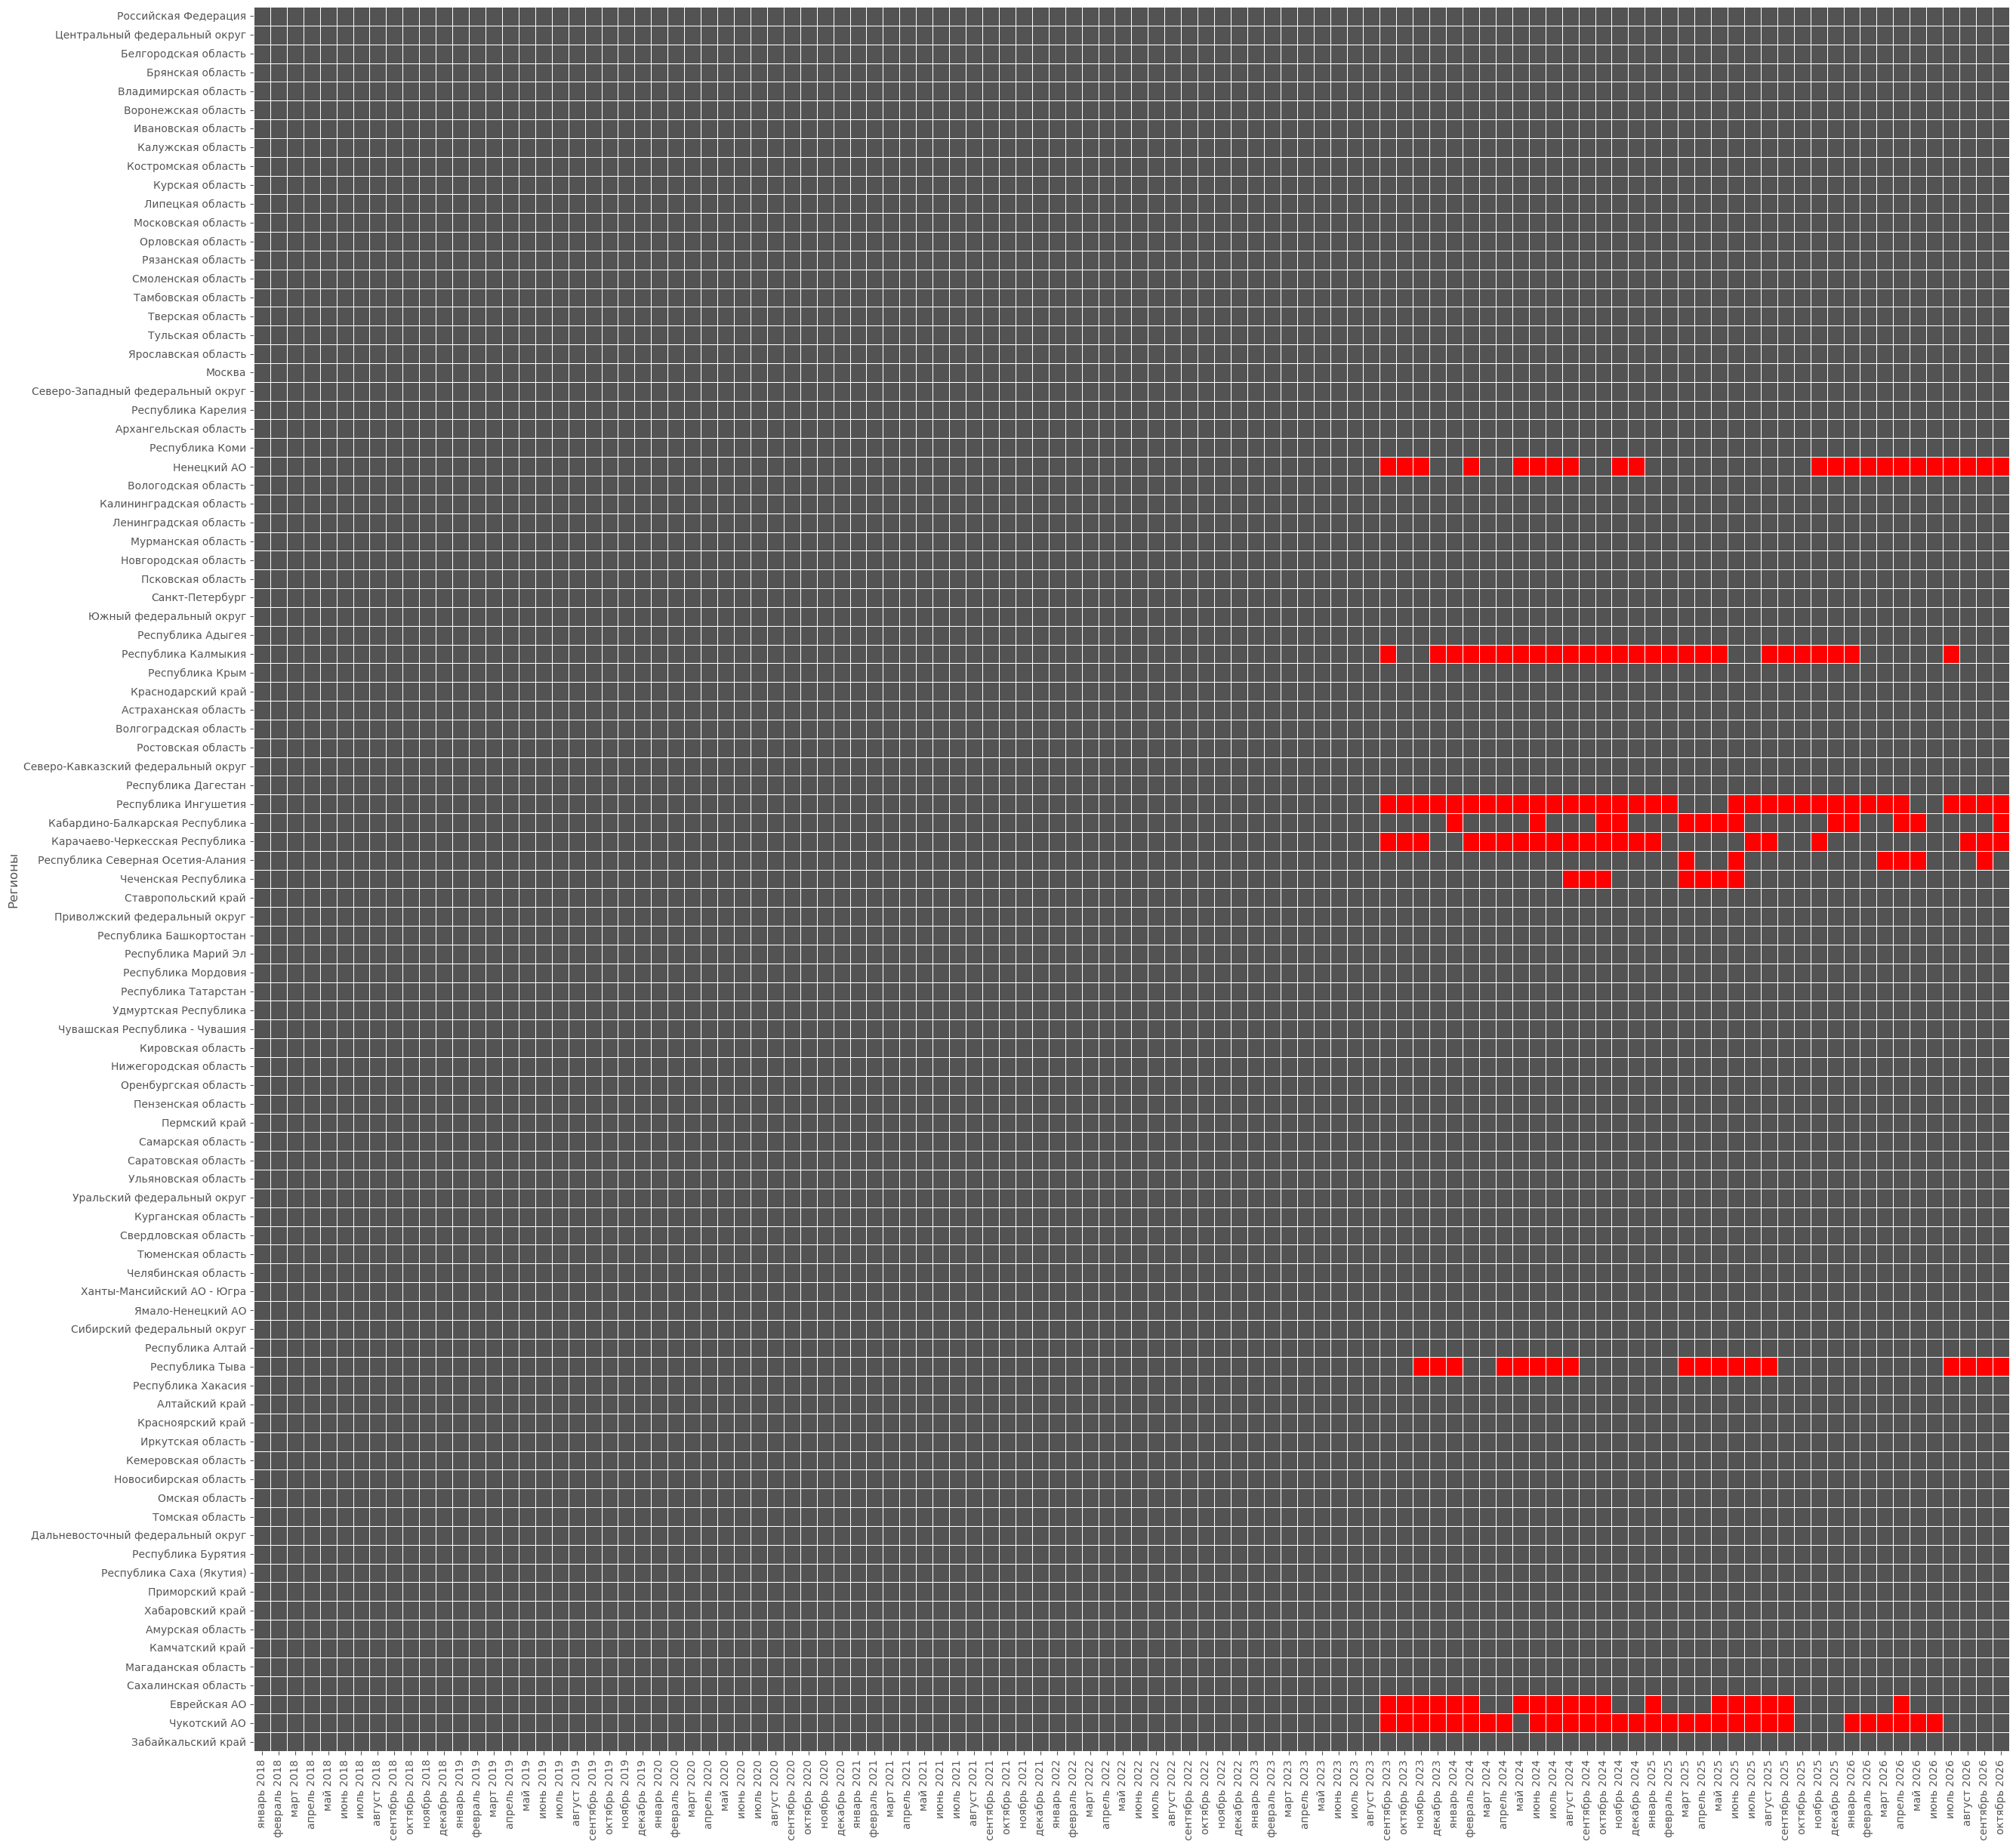

In [ ]:
# Missing data
# Map of missing values

cols = df_y.columns
# define cols
# red - missing, grey - present
colours = ["#535353", "#ff0000"]
sns.heatmap(df_y[cols].isnull(), cmap=sns.color_palette(colours), cbar=False, linewidths=0.5, linecolor='white')
plt.savefig(f'{PARENT_PLOT_DIR}\\Missing_heatmap\\HeatMapY')
plt.show()

In [15]:
# generate and save heatmaps for every X
colours = ["#535353", "#ff0000"]

for i in range (0, 13):
    cols = DATA_LIST[i].columns
    sns.heatmap(DATA_LIST[i][cols].isnull(), cmap=sns.color_palette(colours), cbar=False, linewidths=0.5, linecolor='white')
    plt.savefig(f'{PARENT_PLOT_DIR}\\Missing_heatmap\\HeatMapX{i+1}')